# Introduction to Linear Algebra — SVD on images (lab)

In this notebook we explore **SVD (Singular Value Decomposition)** on images.
It runs **locally** (no Google Colab / Google Drive).

Goals:
1. load any local image and compute its SVD,
2. check how many of the largest singular values are enough for a decent reconstruction,
3. check what happens if we **skip the first** components (use the 10th, 11th, …, k+10th),
4. compare satellite scenes of different terrains: forest / urban / ocean.


## 1. Imports

We use `PIL` to load images, `numpy` for matrices/SVD, and `matplotlib` for plots.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from PIL import Image

%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)


## 2. Helper functions

A color image is converted to **grayscale**, so we can treat it as a 2D matrix `A` of size m×n.
SVD: `A = U Σ Vᵀ`. The rank-k approximation keeps only the `k` largest singular values:

`A_k = U[:, :k] * diag(σ[:k]) * V[:k, :]`


In [2]:
def load_gray(path, max_side=400):
    '''Load an image, convert to grayscale, optionally downscale for faster SVD.'''
    img = Image.open(path).convert('L')
    w, h = img.size
    scale = max_side / max(w, h)
    if scale < 1:
        img = img.resize((int(w * scale), int(h * scale)), Image.Resampling.LANCZOS)
    return np.asarray(img, dtype=float)


def reconstruct(U, sigma, Vh, j, i):
    '''Reconstruct using singular components with indices from j to i (exclusive).'''
    return (U[:, j:i] * sigma[j:i]) @ Vh[j:i, :]


def relative_error(original, approx):
    return np.linalg.norm(original - approx) / np.linalg.norm(original)


def energy_captured(sigma, k):
    return np.sum(sigma[:k] ** 2) / np.sum(sigma ** 2)


## 3. Test on any local image

The path points to a file in `images/`. Change it to any image on your disk.


shape: (400, 400)


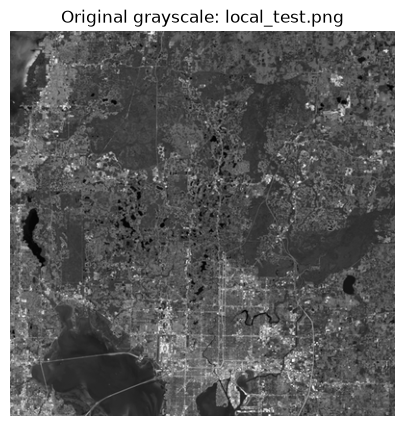

In [3]:
IMG_DIR = Path('images')
LOCAL_IMG = IMG_DIR / 'local_test.png'

imgmat = load_gray(LOCAL_IMG)
print('shape:', imgmat.shape)

plt.imshow(imgmat, cmap='gray')
plt.title(f'Original grayscale: {LOCAL_IMG.name}')
plt.axis('off')
plt.show()


### SVD — reconstruction with 1 component

The first (largest) singular value usually carries most of the image energy —
overall contrast / brightness / coarse structure.


U: (400, 400) | sigma: (400,) | Vh: (400, 400)


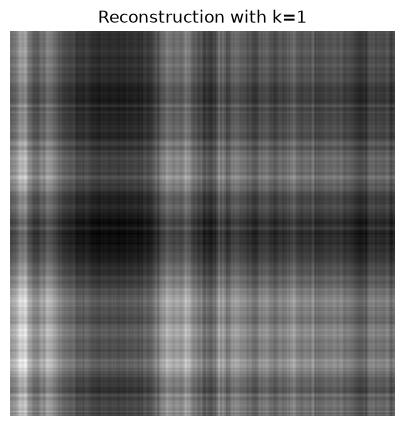

In [4]:
U, sigma, Vh = np.linalg.svd(imgmat, full_matrices=False)
print('U:', U.shape, '| sigma:', sigma.shape, '| Vh:', Vh.shape)

reconst = reconstruct(U, sigma, Vh, 0, 1)
plt.imshow(reconst, cmap='gray')
plt.title('Reconstruction with k=1')
plt.axis('off')
plt.show()


### Singular value spectrum (`sigma`)

Observation: `sigma` usually **decays quickly**. The first values are large, later ones get smaller —
that is why low-rank compression works.


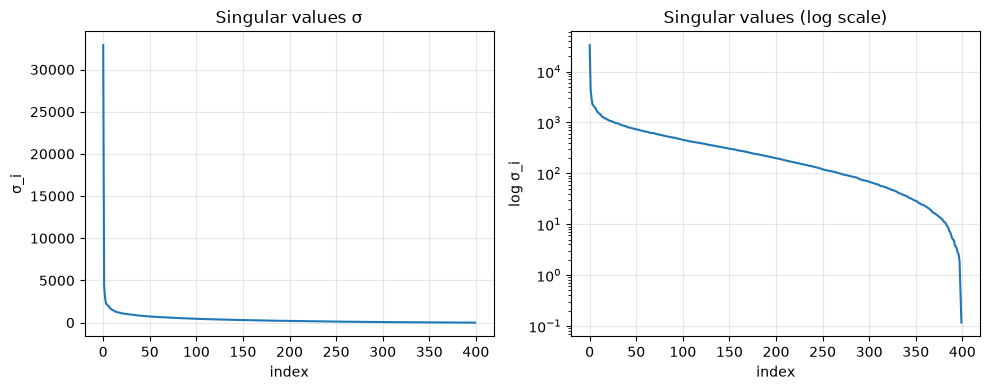

k needed for 90% energy: 2
k needed for 95% energy: 16
k needed for 99% energy: 101


In [5]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(sigma)
plt.title('Singular values σ')
plt.xlabel('index')
plt.ylabel('σ_i')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.semilogy(sigma)
plt.title('Singular values (log scale)')
plt.xlabel('index')
plt.ylabel('log σ_i')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

cum = np.cumsum(sigma ** 2) / np.sum(sigma ** 2)
for thr in (0.90, 0.95, 0.99):
    k = int(np.searchsorted(cum, thr) + 1)
    print(f'k needed for {int(thr*100)}% energy: {k}')


### How many components are enough? Compare different `k`

Larger `k` improves quality, but the gain quickly diminishes.


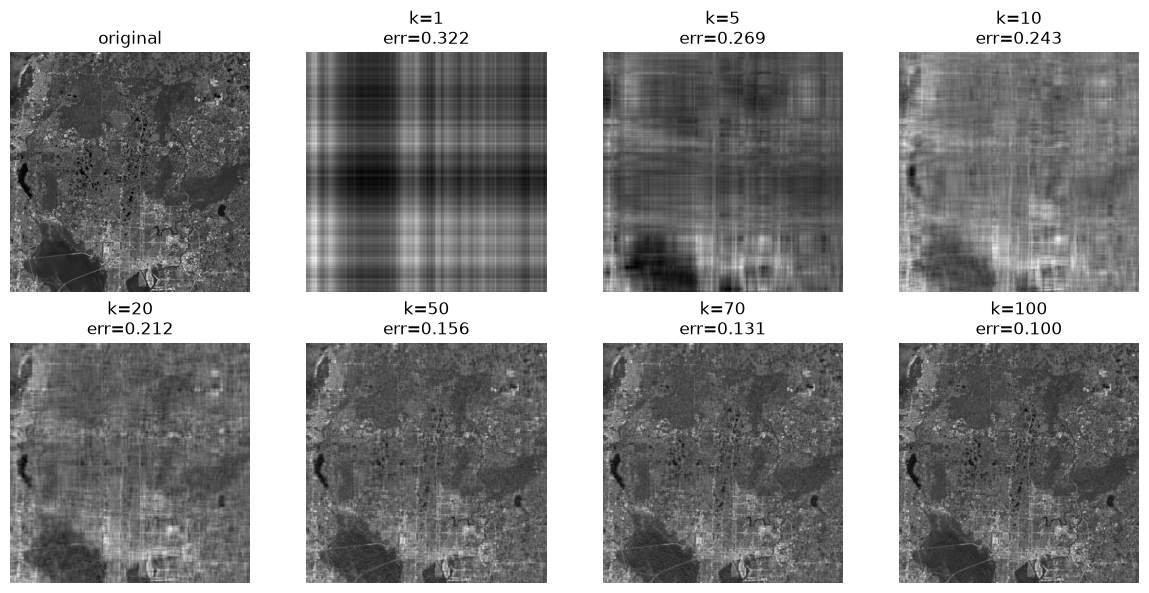

In [6]:
ks = [1, 5, 10, 20, 50, 70, 100]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.ravel()

axes[0].imshow(imgmat, cmap='gray')
axes[0].set_title('original')
axes[0].axis('off')

for ax, k in zip(axes[1:], ks):
    approx = reconstruct(U, sigma, Vh, 0, k)
    err = relative_error(imgmat, approx)
    ax.imshow(approx, cmap='gray')
    ax.set_title(f'k={k}\nerr={err:.3f}')
    ax.axis('off')

plt.tight_layout()
plt.show()


## 4. Key question: largest `k` vs skipping the first 10

Instead of using `σ_1 … σ_k`, we use `σ_11 … σ_{k+10}` (that is `j=10`, `i=k+10`).

**Hypothesis before the experiment:** this should be WORSE, because we discard the components with the largest energy.


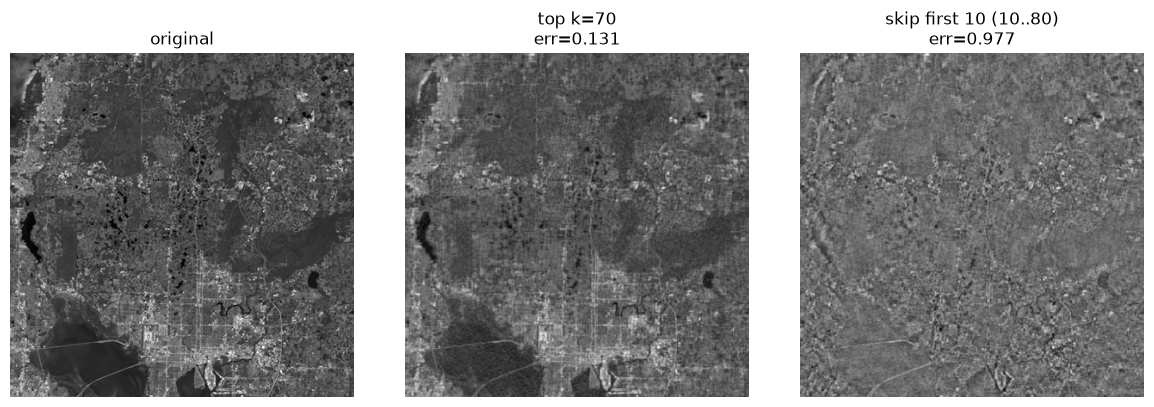

Conclusion: skipping the largest σ ruins the image — we do NOT get better quality.


In [7]:
k = 70
best = reconstruct(U, sigma, Vh, 0, k)           # largest k
shifted = reconstruct(U, sigma, Vh, 10, k + 10)  # 10 .. k+10

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(imgmat, cmap='gray')
axes[0].set_title('original')
axes[0].axis('off')

axes[1].imshow(best, cmap='gray')
axes[1].set_title(f'top k={k}\nerr={relative_error(imgmat, best):.3f}')
axes[1].axis('off')

axes[2].imshow(shifted, cmap='gray')
axes[2].set_title(f'skip first 10 (10..{k+10})\nerr={relative_error(imgmat, shifted):.3f}')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print('Conclusion: skipping the largest σ ruins the image — we do NOT get better quality.')


## 5. Satellite images of different terrains

We compare: **forest / urban / ocean**.
Paths point to real NASA / USGS satellite images in `images/`
(you can also replace them with your own images from previous courses).

Sources (public domain / NASA — details in `IMAGE_SOURCES.md`):
- forest: Amazon rainforest, MODIS / NASA
- urban: Tampa Bay, Landsat 8 natural-color composite (USGS/NASA)
- ocean: Atlantic phytoplankton bloom off Brittany, MODIS / NASA Aqua


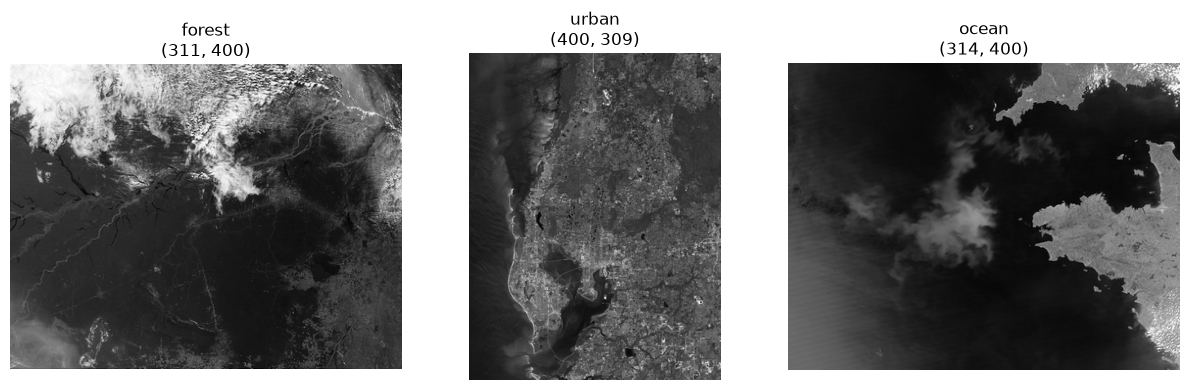

In [8]:
terrain_paths = {
    'forest': IMG_DIR / 'forest.jpg',
    'urban':  IMG_DIR / 'urban.jpg',
    'ocean':  IMG_DIR / 'ocean.jpg',
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, path) in zip(axes, terrain_paths.items()):
    A = load_gray(path)
    ax.imshow(A, cmap='gray')
    ax.set_title(f'{name}\n{A.shape}')
    ax.axis('off')
plt.tight_layout()
plt.show()


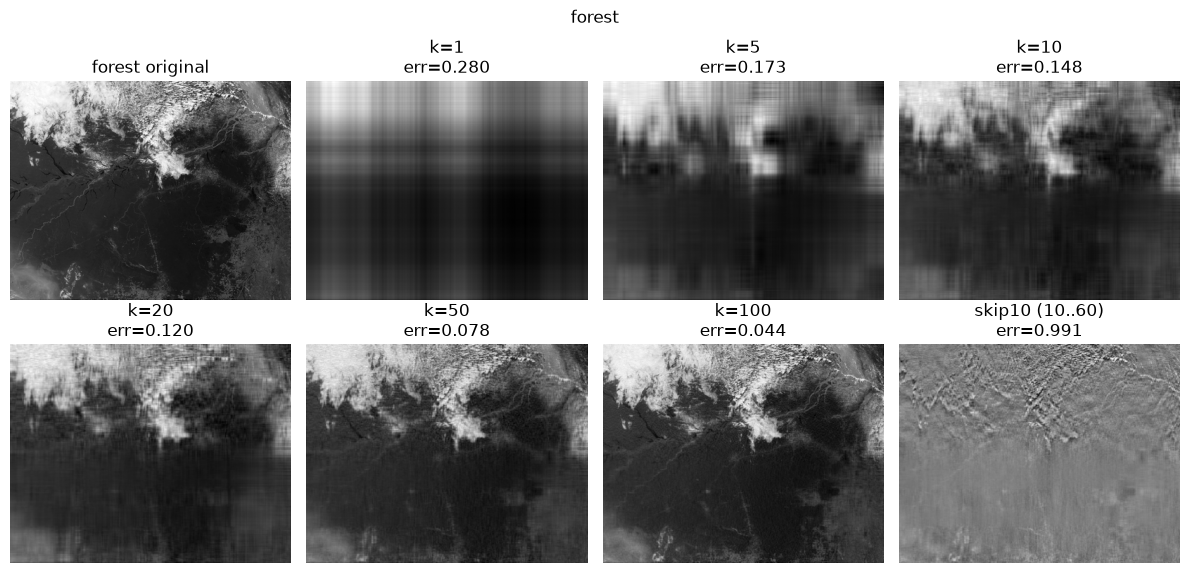

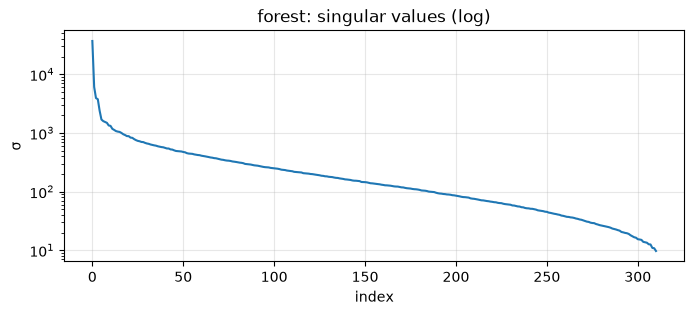

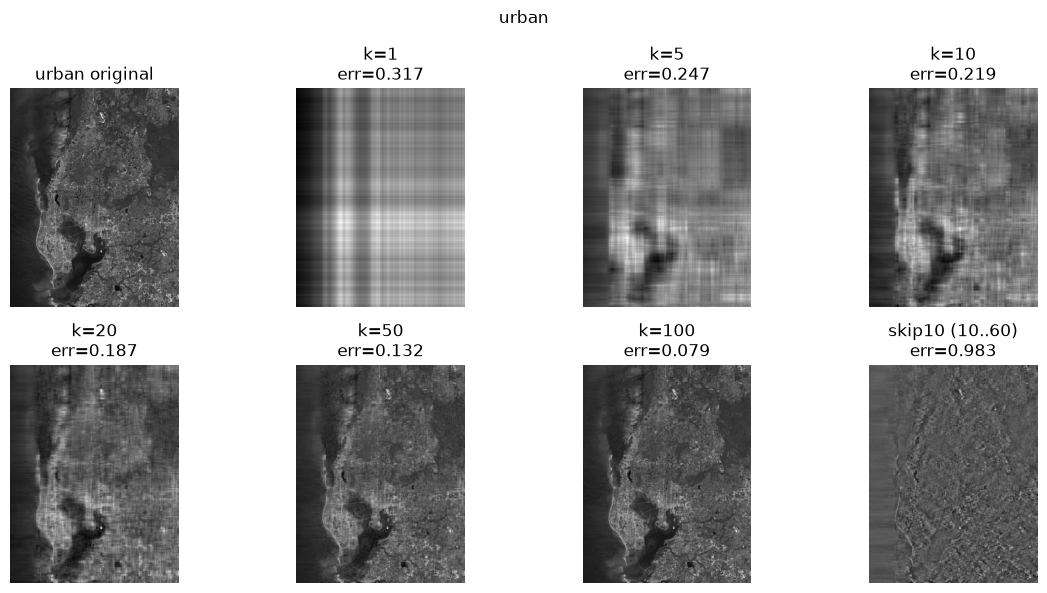

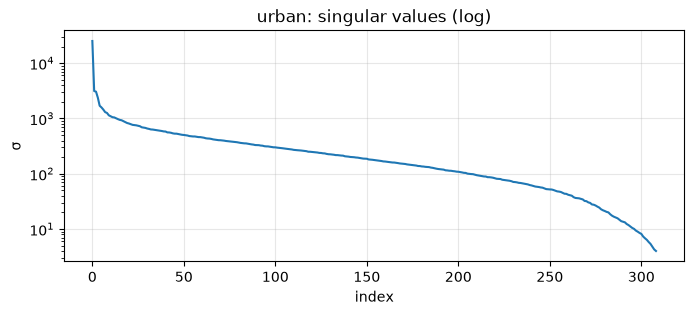

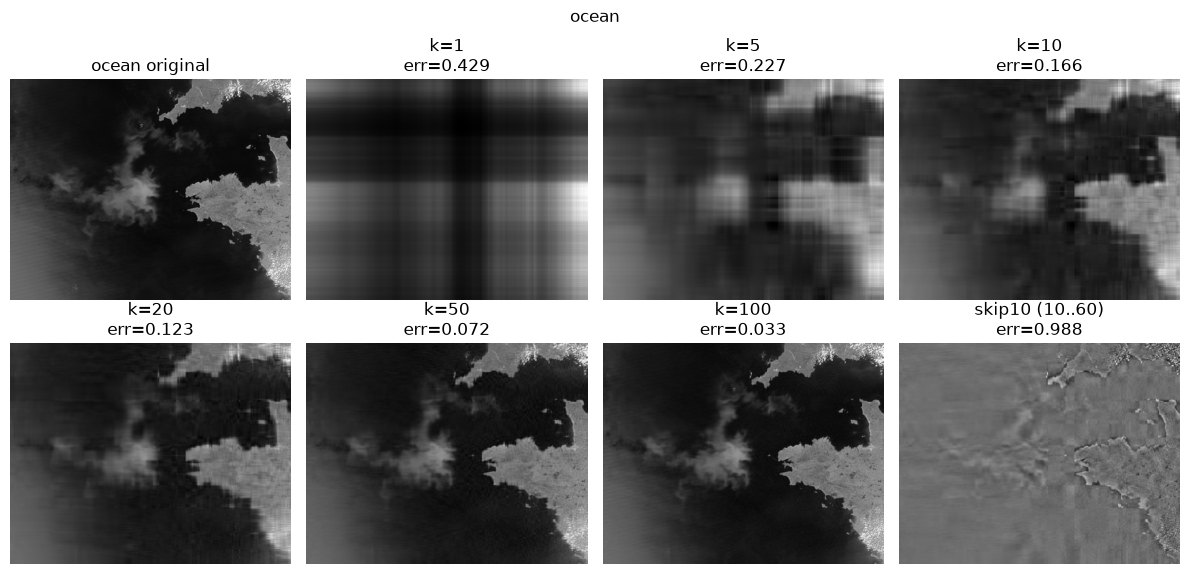

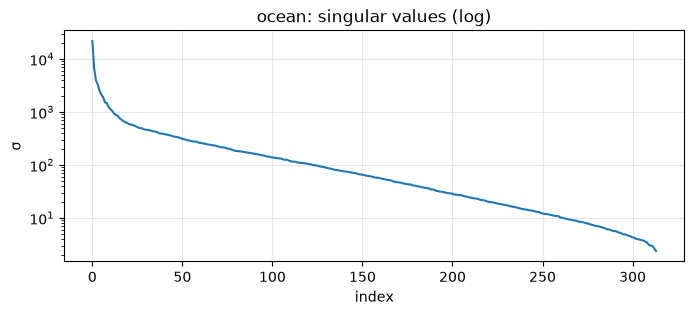

name | shape | k90% | k95% | k99% | k(err<0.1) | k(err<0.05)
forest  | (311, 400) |    1 |    3 |   32 |         32 | 88
urban   | (400, 309) |    2 |    9 |   78 |         78 | 142
ocean   | (314, 400) |    3 |    6 |   32 |         32 | 73


In [9]:
ks = [1, 5, 10, 20, 50, 100]
summary = []

for name, path in terrain_paths.items():
    A = load_gray(path)
    U_t, s_t, Vh_t = np.linalg.svd(A, full_matrices=False)
    cum = np.cumsum(s_t ** 2) / np.sum(s_t ** 2)
    k90 = int(np.searchsorted(cum, 0.90) + 1)
    k95 = int(np.searchsorted(cum, 0.95) + 1)
    k99 = int(np.searchsorted(cum, 0.99) + 1)

    k_err10 = k_err05 = None
    for k in range(1, len(s_t) + 1):
        err = relative_error(A, reconstruct(U_t, s_t, Vh_t, 0, k))
        if k_err10 is None and err < 0.10:
            k_err10 = k
        if k_err05 is None and err < 0.05:
            k_err05 = k
            break

    summary.append((name, A.shape, k90, k95, k99, k_err10, k_err05))

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    axes = axes.ravel()
    axes[0].imshow(A, cmap='gray')
    axes[0].set_title(f'{name} original')
    axes[0].axis('off')

    for ax, k in zip(axes[1:], ks):
        approx = reconstruct(U_t, s_t, Vh_t, 0, k)
        ax.imshow(approx, cmap='gray')
        ax.set_title(f'k={k}\nerr={relative_error(A, approx):.3f}')
        ax.axis('off')

    skip = reconstruct(U_t, s_t, Vh_t, 10, 60)
    axes[-1].imshow(skip, cmap='gray')
    axes[-1].set_title(f'skip10 (10..60)\nerr={relative_error(A, skip):.3f}')
    axes[-1].axis('off')
    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 3))
    plt.semilogy(s_t)
    plt.title(f'{name}: singular values (log)')
    plt.xlabel('index')
    plt.ylabel('σ')
    plt.grid(True, alpha=0.3)
    plt.show()

print('name | shape | k90% | k95% | k99% | k(err<0.1) | k(err<0.05)')
for row in summary:
    print(f'{row[0]:7s} | {row[1]} | {row[2]:4d} | {row[3]:4d} | {row[4]:4d} | {row[5]:10} | {row[6]}')


## 6. Short conclusions (for the report)

- **How many singular values are enough?** It depends on the image. Smooth ocean scenes need few components; highly textured / detailed scenes need more.
- **Is using the 10th, 11th, …, k+10th better?** No. It is clearly worse — the largest `σ` carry the main structure (brightness, large shapes). Without them you mostly keep fine detail / noise.
- **Different terrains:** smooth / homogeneous scenes compress better (smaller `k`); scenes with high spatial variability need larger `k` to avoid perceptual degradation.

